## 1. Introduction

This project uses the Customer Personality Analysis dataset from Kaggle. The dataset contains customer demographic information, product spending behaviour, purchase channel activity, marketing campaign responses, and complaint records. Each row represents one customer, and each column describes one customer attribute or behaviour.

The original dataset contains 2240 customer records and 29 columns. The dataset is suitable for exploratory data analysis because it includes both demographic variables, such as `Education`, `Marital_Status`, `Income`, and `Year_Birth`, and behavioural variables, such as product spending, purchase frequency, website visits, and campaign acceptance.

The aim of this project is to explore customer behaviour and identify meaningful customer segments. The analysis focuses on data processing, visualisation, feature engineering, PCA, and K-Means clustering. These methods are used to understand which customer characteristics are associated with higher spending and to summarise the customer base into interpretable groups.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [5]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [6]:
df.shape

(2240, 29)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

## 2. Data Processing

This section prepares the dataset for analysis. The raw data was inspected for missing values, duplicate records, constant columns, incorrect data types, and unrealistic outliers. These checks are important because later techniques such as PCA and K-Means clustering require clean numerical data.

### 2.1 Initial data checks

The dataset structure was checked using shape, column information, missing values, and duplicate records. This confirmed the number of samples and variables and identified any cleaning steps needed before analysis.

In [8]:
df.isnull().sum().sort_values(ascending=False)

Income                 24
ID                      0
NumDealsPurchases       0
Z_Revenue               0
Z_CostContact           0
Complain                0
AcceptedCmp2            0
AcceptedCmp1            0
AcceptedCmp5            0
AcceptedCmp4            0
AcceptedCmp3            0
NumWebVisitsMonth       0
NumStorePurchases       0
NumCatalogPurchases     0
NumWebPurchases         0
MntGoldProds            0
Year_Birth              0
MntSweetProducts        0
MntFishProducts         0
MntMeatProducts         0
MntFruits               0
MntWines                0
Recency                 0
Dt_Customer             0
Teenhome                0
Kidhome                 0
Marital_Status          0
Education               0
Response                0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

### 2.2 Missing value handling

Only the `Income` column contained missing values. These missing values were replaced using the median income rather than the mean, because income data can be affected by extreme high values. Median imputation preserves all customer records while reducing the influence of outliers.

In [10]:
df_clean = df.copy()

income_median = df_clean["Income"].median()
df_clean["Income"] = df_clean["Income"].fillna(income_median)

df_clean["Income"].isnull().sum()

np.int64(0)

After median imputation, the `Income` column contained 0 missing values, so all customer records were retained for later analysis. The median was used instead of the mean because income is often right-skewed and can be affected by very high values. Using the median gives a more robust estimate of a typical customer income and reduces the chance that extreme income values distort the replacement value.

### 2.3 Removing irrelevant and constant columns

The `ID` column is a unique customer identifier, so it does not provide behavioural information for analysis. The columns `Z_CostContact` and `Z_Revenue` were also checked because they appeared to contain constant values. Constant columns provide no variation and therefore cannot help visualisation, PCA, or clustering.

In [11]:
df_clean.nunique().sort_values()

Z_Revenue                 1
Z_CostContact             1
Response                  2
AcceptedCmp3              2
AcceptedCmp4              2
AcceptedCmp2              2
Complain                  2
AcceptedCmp1              2
AcceptedCmp5              2
Kidhome                   3
Teenhome                  3
Education                 5
Marital_Status            8
NumCatalogPurchases      14
NumStorePurchases        14
NumDealsPurchases        15
NumWebPurchases          15
NumWebVisitsMonth        16
Year_Birth               59
Recency                 100
MntFruits               158
MntSweetProducts        177
MntFishProducts         182
MntGoldProds            213
MntMeatProducts         558
Dt_Customer             663
MntWines                776
Income                 1975
ID                     2240
dtype: int64

In [12]:
df_clean = df_clean.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])

df_clean.shape

(2240, 26)

`Z_CostContact` and `Z_Revenue` each had only one unique value, so they were removed along with the unique customer ID. After this step, the dataset contained 2240 rows and 26 columns.

### 2.4 Date conversion

The `Dt_Customer` column was converted from text into datetime format. This allows customer tenure to be calculated correctly from the enrolment dates.

In [13]:
df_clean["Dt_Customer"] = pd.to_datetime(df_clean["Dt_Customer"], dayfirst=True)

df_clean["Dt_Customer"].head()

0   2012-09-04
1   2014-03-08
2   2013-08-21
3   2014-02-10
4   2014-01-19
Name: Dt_Customer, dtype: datetime64[ns]

The enrolment date is now stored as a datetime column, making it possible to calculate customer tenure in months during feature engineering.

### 2.5 Outlier handling

Outliers were checked before visualisation because extreme values can distort plots, summary statistics, PCA, and clustering. Income was inspected for unusually high values, and age was checked using `Year_Birth` and the latest customer enrolment year in the dataset.

In [14]:
reference_year = df_clean["Dt_Customer"].dt.year.max()   # Created temporrary age for outlier checking
df_clean["Temp_Age"] = reference_year - df_clean["Year_Birth"]

df_clean[["Income", "Temp_Age"]].describe()

,Income,Temp_Age
count,2240.000000,2240.000000
mean,52237.975446,45.194196
std,25037.955891,11.984069
min,1730.000000,18.000000
25%,35538.750000,37.000000
50%,51381.500000,44.000000
75%,68289.750000,55.000000
max,666666.000000,121.000000


In [15]:
df_clean[
    (df_clean["Temp_Age"] >= 100) | (df_clean["Income"] >= 200000)  # Searching suspicious age,income outliers
][["Year_Birth", "Temp_Age", "Income"]]

,Year_Birth,Temp_Age,Income
192,1900,114,36640.0
239,1893,121,60182.0
339,1899,115,83532.0
2233,1977,37,666666.0


In [16]:
df_clean = df_clean[df_clean["Temp_Age"] < 100].copy() # Removing unrealistic age, income outliers
df_clean = df_clean[df_clean["Income"] < 200000].copy()

df_clean = df_clean.drop(columns=["Temp_Age"])

df_clean["Income"].describe()

count      2236.000000
mean      51952.614043
std       21411.466851
min        1730.000000
25%       35502.500000
50%       51381.500000
75%       68275.750000
max      162397.000000
Name: Income, dtype: float64

After removing the extreme income and unrealistic age outliers, the cleaned dataset contains 2236 customer records. The income distribution is now more realistic, with a maximum income of 162,397 instead of the original extreme value of 666,666. The mean and median income are also close, suggesting that the cleaned income variable is less distorted by extreme values.

## 3. Data Visualization

This section visualises the cleaned dataset before the main feature engineering stage. Most plots use original/raw variables such as income, product spending columns, purchase channels, campaign response, and demographic categories. 


### 3.1 Income distribution and spread

The distribution of customer income was visualised using both a histogram and a boxplot. The histogram shows the overall shape of the income distribution, while the boxplot highlights the spread and remaining high-income values after cleaning.

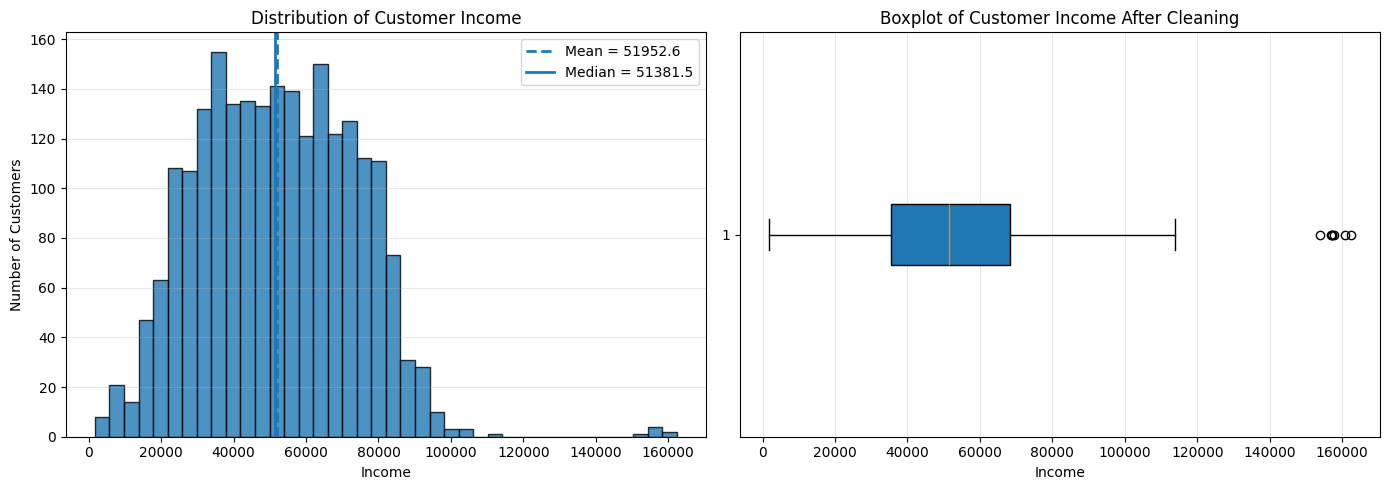

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_clean["Income"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

axes[0].axvline(
    df_clean["Income"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {df_clean['Income'].mean():.1f}"
)

axes[0].axvline(
    df_clean["Income"].median(),
    linestyle="-",
    linewidth=2,
    label=f"Median = {df_clean['Income'].median():.1f}"
)

axes[0].set_xlabel("Income")
axes[0].set_ylabel("Number of Customers")
axes[0].set_title("Distribution of Customer Income")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

axes[1].boxplot(
    df_clean["Income"],
    vert=False,
    patch_artist=True
)

axes[1].set_xlabel("Income")
axes[1].set_title("Boxplot of Customer Income After Cleaning")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig("income_distribution_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

The histogram shows that customer income is concentrated mainly in the middle-income range, with fewer customers at very low or very high income levels. The mean and median are fairly close, which suggests that the cleaned income distribution is less distorted after removing the extreme income outlier. The boxplot confirms that although some high-income values remain, they are much less extreme and appear plausible enough to retain for later analysis.

### 3.2 Summary visualisation of raw customer behaviour

To give a compact overview of the cleaned raw dataset, four related visualisations were grouped together in one figure. These plots summarise product spending, purchase channels, education-level spending differences, and campaign response behaviour before the main feature engineering stage.

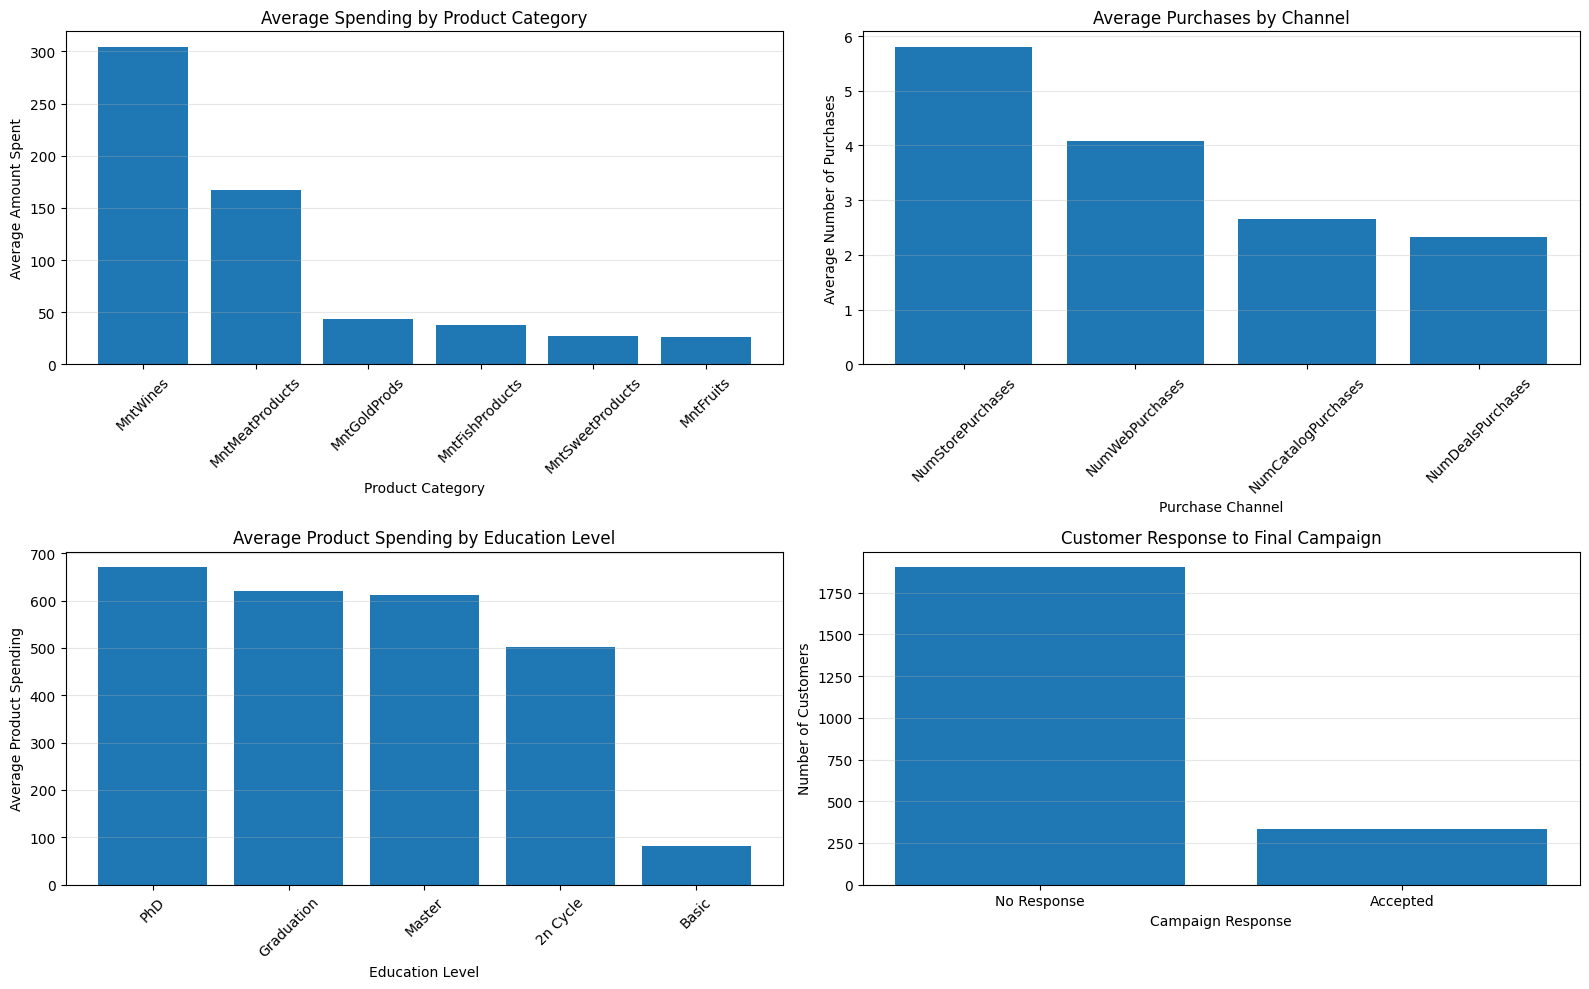

In [18]:
product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

purchase_cols = [
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]


product_spending = df_clean[product_cols].mean().sort_values(ascending=False)

purchase_channel_means = df_clean[purchase_cols].mean().sort_values(ascending=False)

education_product_spending = (
    df_clean
    .assign(Product_Spending_For_Plot=df_clean[product_cols].sum(axis=1))
    .groupby("Education")["Product_Spending_For_Plot"]
    .mean()
    .sort_values(ascending=False)
)

response_counts = df_clean["Response"].value_counts().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].bar(product_spending.index, product_spending.values)
axes[0, 0].set_title("Average Spending by Product Category")
axes[0, 0].set_xlabel("Product Category")
axes[0, 0].set_ylabel("Average Amount Spent")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(axis="y", alpha=0.3)

axes[0, 1].bar(purchase_channel_means.index, purchase_channel_means.values)
axes[0, 1].set_title("Average Purchases by Channel")
axes[0, 1].set_xlabel("Purchase Channel")
axes[0, 1].set_ylabel("Average Number of Purchases")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(axis="y", alpha=0.3)

axes[1, 0].bar(education_product_spending.index, education_product_spending.values)
axes[1, 0].set_title("Average Product Spending by Education Level")
axes[1, 0].set_xlabel("Education Level")
axes[1, 0].set_ylabel("Average Product Spending")
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].grid(axis="y", alpha=0.3)

axes[1, 1].bar(["No Response", "Accepted"], response_counts.values)
axes[1, 1].set_title("Customer Response to Final Campaign")
axes[1, 1].set_xlabel("Campaign Response")
axes[1, 1].set_ylabel("Number of Customers")
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig("raw_customer_behaviour_summary.png", dpi=300, bbox_inches="tight")
plt.show()

The combined visualisation shows several important patterns in the raw data. Wine and meat products have the highest average spending, suggesting that these are major contributors to customer value. Store and web purchases are among the most common purchase channels, showing that customers use multiple buying routes. Spending also varies across education groups, with some education categories showing higher average product spending than others. Finally, the campaign response chart shows that most customers did not accept the final campaign, indicating that positive campaign response is relatively uncommon.

## 4. Feature Engineering

Feature engineering was used to create more meaningful customer-level variables from the raw dataset. The original dataset contains many separate columns for product spending, purchase channels, household information, and campaign responses. These were combined into summary features that are easier to interpret and more useful for PCA and clustering.

The engineered features created in this section are:

- `Age`: customer age at the time of the dataset.
- `Customer_Tenure_Months`: number of months between customer enrolment and the latest enrolment date in the dataset.
- `Total_Children`: total number of children and teenagers in the household.
- `Total_Spending`: total spending across all product categories.
- `Total_Purchases`: total purchases across deal, web, catalogue, and store channels.
- `Accepted_Campaigns`: total number of accepted marketing campaigns, including the final response.

In [19]:
reference_year = df_clean["Dt_Customer"].dt.year.max()
reference_date = df_clean["Dt_Customer"].max()

df_clean["Age"] = reference_year - df_clean["Year_Birth"]

df_clean["Customer_Tenure_Months"] = (
    (reference_date.year - df_clean["Dt_Customer"].dt.year) * 12
    + (reference_date.month - df_clean["Dt_Customer"].dt.month)
)

df_clean["Total_Children"] = df_clean["Kidhome"] + df_clean["Teenhome"]

df_clean["Total_Spending"] = (      # Totalspending on product
    df_clean["MntWines"] +
    df_clean["MntFruits"] +
    df_clean["MntMeatProducts"] +
    df_clean["MntFishProducts"] +
    df_clean["MntSweetProducts"] +
    df_clean["MntGoldProds"]
)

df_clean["Total_Purchases"] = (    # Total purchasess channel
    df_clean["NumDealsPurchases"] +
    df_clean["NumWebPurchases"] +
    df_clean["NumCatalogPurchases"] +
    df_clean["NumStorePurchases"]
)

df_clean["Accepted_Campaigns"] = (      # Total accepted marketing campaigns
    df_clean["AcceptedCmp1"] +
    df_clean["AcceptedCmp2"] +
    df_clean["AcceptedCmp3"] +
    df_clean["AcceptedCmp4"] +
    df_clean["AcceptedCmp5"] +
    df_clean["Response"]
)

df_clean[[
    "Age",
    "Customer_Tenure_Months",
    "Total_Children",
    "Total_Spending",
    "Total_Purchases",
    "Accepted_Campaigns"
]].head()

,Age,Customer_Tenure_Months,Total_Children,Total_Spending,Total_Purchases,Accepted_Campaigns
0,57,21,0,1617,25,1
1,60,3,2,27,6,0
2,49,10,0,776,21,0
3,30,4,1,53,8,0
4,33,5,1,422,19,0


The new engineered features provide a more compact description of each customer. For example, the product spending columns are summarised into `Total_Spending`, while the purchase channel columns are summarised into `Total_Purchases`. This reduces complexity and makes later analysis easier to interpret.

In [20]:
engineered_features = [
    "Age",
    "Customer_Tenure_Months",
    "Total_Children",
    "Total_Spending",
    "Total_Purchases",
    "Accepted_Campaigns"
]

df_clean[engineered_features].describe()

,Age,Customer_Tenure_Months,Total_Children,Total_Spending,Total_Purchases,Accepted_Campaigns
count,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000
mean,45.101968,11.201252,0.950805,605.986583,14.872540,0.447227
std,11.703281,6.641994,0.752204,601.865156,7.677874,0.891113
min,18.000000,0.000000,0.000000,5.000000,0.000000,0.000000
25%,37.000000,6.000000,0.000000,69.000000,8.000000,0.000000
50%,44.000000,11.000000,1.000000,396.500000,15.000000,0.000000
75%,55.000000,17.000000,1.000000,1045.500000,21.000000,1.000000
max,74.000000,23.000000,3.000000,2525.000000,44.000000,5.000000


The engineered feature summary shows that customer ages range from 18 to 74 after outlier removal. Customer tenure ranges from 0 to 23 months, showing variation in how long customers have been enrolled. Total spending is right-skewed because the mean is higher than the median, suggesting that a smaller group of customers spend much more than the typical customer. Campaign acceptance is generally low, with a median of 0, meaning most customers did not accept any campaigns.

In [21]:
df_clean = df_clean[df_clean["Age"] < 100].copy()
df_clean = df_clean[df_clean["Income"] < 200000].copy()

df_clean[["Income", "Age"]].describe()

,Income,Age
count,2236.000000,2236.000000
mean,51952.614043,45.101968
std,21411.466851,11.703281
min,1730.000000,18.000000
25%,35502.500000,37.000000
50%,51381.500000,44.000000
75%,68275.750000,55.000000
max,162397.000000,74.000000


In [22]:
print("Cleaned dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows after removing ID:", df_clean.duplicated().sum())

Cleaned dataset shape: (2236, 32)
Total missing values: 0
Duplicate rows after removing ID: 182


### Duplicate record interpretation

Before removing the unique customer identifier (`ID`), the dataset was checked for exact duplicate rows and no full duplicate records were found. After removing `ID`, some rows became identical across the remaining variables. These were not treated as true duplicates because they may represent different customers who happen to share the same recorded characteristics, such as the same demographic values, spending amounts, and campaign responses. Therefore, these rows were retained to avoid incorrectly removing valid customer records.

### Distribution of total spending

The `Total_Spending` feature was visualised to understand the overall spending behaviour of customers after combining all product spending columns.

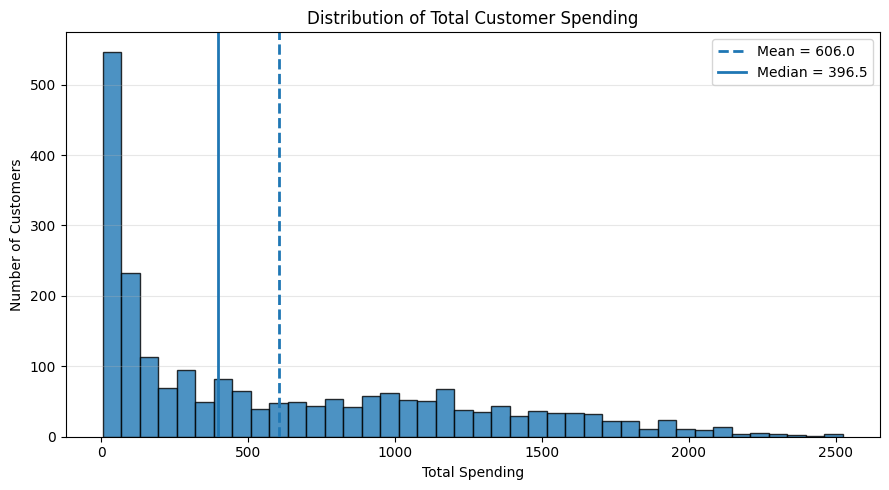

In [23]:
mean_spending = df_clean["Total_Spending"].mean()
median_spending = df_clean["Total_Spending"].median()

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["Total_Spending"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(mean_spending, linestyle="--", linewidth=2, label=f"Mean = {mean_spending:.1f}")
plt.axvline(median_spending, linestyle="-", linewidth=2, label=f"Median = {median_spending:.1f}")

plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.title("Distribution of Total Customer Spending")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("total_spending_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

The total spending distribution is strongly right-skewed. Most customers spend relatively low to moderate amounts, while a smaller group spends much more. The mean is higher than the median, confirming that high-spending customers pull the average upward. These high-spending customers were retained because they may represent valuable customer segments rather than data errors.

### Boxplot of total spending

A boxplot was used to examine the spread of total customer spending and identify high-spending observations. These observations were inspected but retained because high spending may represent valuable customers rather than data errors.

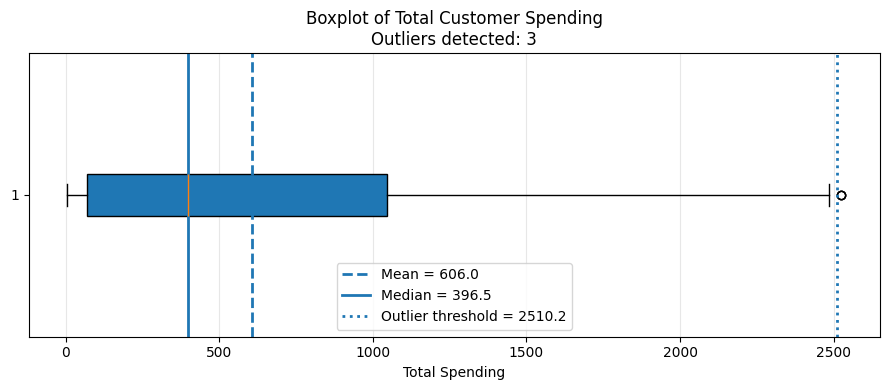

In [24]:
Q1 = df_clean["Total_Spending"].quantile(0.25)
Q3 = df_clean["Total_Spending"].quantile(0.75)
IQR = Q3 - Q1
upper_threshold = Q3 + 1.5 * IQR

outlier_count = (df_clean["Total_Spending"] > upper_threshold).sum()

mean_spending = df_clean["Total_Spending"].mean()
median_spending = df_clean["Total_Spending"].median()

plt.figure(figsize=(9, 4))

plt.boxplot(
    df_clean["Total_Spending"],
    vert=False,
    patch_artist=True
)

plt.axvline(mean_spending, linestyle="--", linewidth=2, label=f"Mean = {mean_spending:.1f}")
plt.axvline(median_spending, linestyle="-", linewidth=2, label=f"Median = {median_spending:.1f}")
plt.axvline(upper_threshold, linestyle=":", linewidth=2, label=f"Outlier threshold = {upper_threshold:.1f}")

plt.xlabel("Total Spending")
plt.title(f"Boxplot of Total Customer Spending\nOutliers detected: {outlier_count}")
plt.grid(axis="x", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

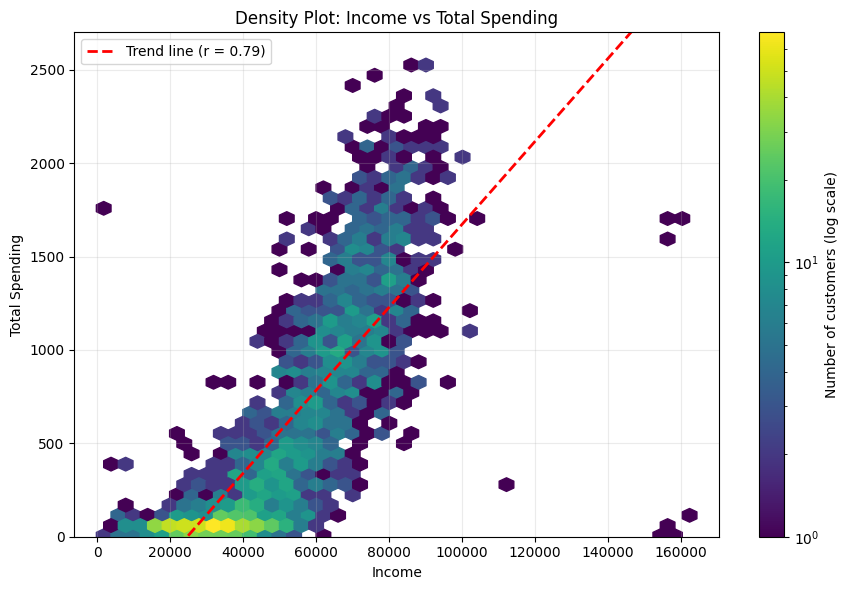

In [25]:
x = df_clean["Income"]
y = df_clean["Total_Spending"]

corr = x.corr(y)

plt.figure(figsize=(9, 6))

hb = plt.hexbin(
    x,
    y,
    gridsize=40,
    cmap="viridis",
    bins="log",
    mincnt=1
)

plt.colorbar(hb, label="Number of customers (log scale)")

m, b = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

plt.plot(
    x_line,
    m * x_line + b,
    linestyle="--",
    linewidth=2,
    color="red",
    label=f"Trend line (r = {corr:.2f})"
)

plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.title("Density Plot: Income vs Total Spending")
plt.legend()
plt.grid(alpha=0.25)
plt.ylim(0, 2700)
plt.tight_layout()
plt.savefig("income_total_spending_density.png", dpi=300, bbox_inches="tight")
plt.show()

The density plot shows a positive relationship between income and total spending. Customers with higher income generally tend to spend more, although there is still variation between customers with similar income levels. The densest region is concentrated among lower- to middle-income customers with lower spending, while fewer customers appear in the high-income and high-spending region.

## Correlation analysis

A correlation heatmap was used to examine relationships between key numerical variables before applying PCA. This helps identify which features move together and whether some variables may be strongly related. Only selected important features were included to keep the heatmap readable.

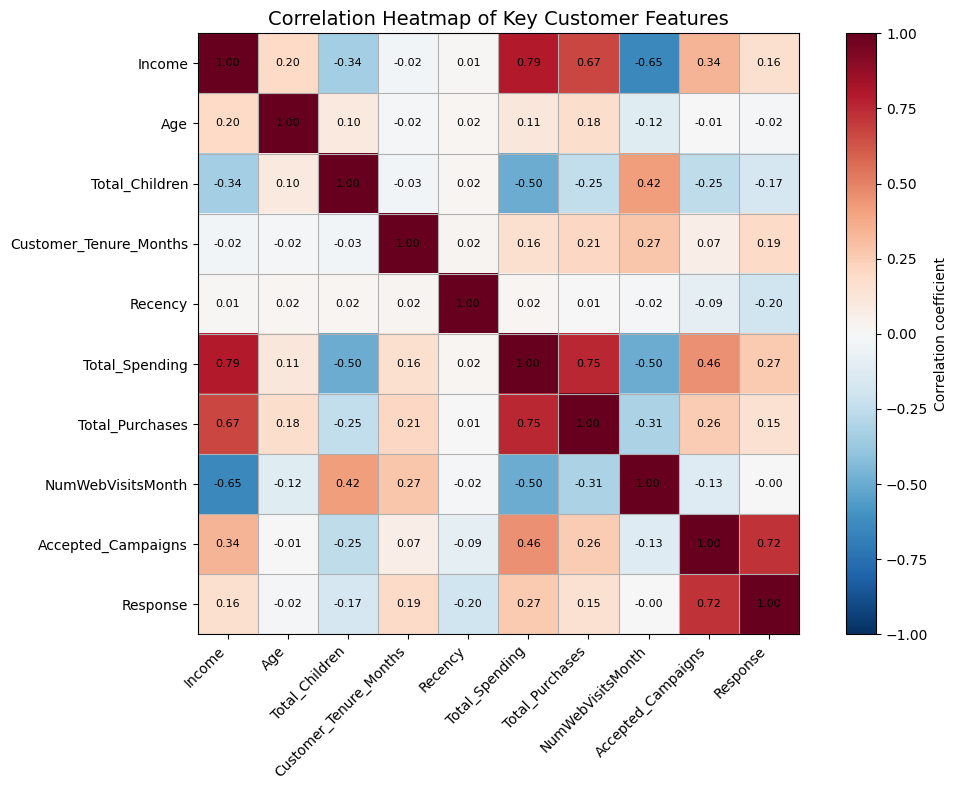

In [26]:
selected_corr_features = [
    "Income", "Age", "Total_Children", "Customer_Tenure_Months",
    "Recency", "Total_Spending", "Total_Purchases",
    "NumWebVisitsMonth", "Accepted_Campaigns", "Response"
]

corr_selected = df_clean[selected_corr_features].corr()

plt.figure(figsize=(11, 8))

plt.imshow(corr_selected, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(selected_corr_features)),
    selected_corr_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(selected_corr_features)),
    selected_corr_features
)

plt.gca().set_xticks(np.arange(-0.5, len(selected_corr_features), 1), minor=True)
plt.gca().set_yticks(np.arange(-0.5, len(selected_corr_features), 1), minor=True)
plt.grid(which="minor", linewidth=0.8)
plt.tick_params(which="minor", bottom=False, left=False)

for i in range(len(selected_corr_features)):
    for j in range(len(selected_corr_features)):
        plt.text(
            j, i,
            f"{corr_selected.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Heatmap of Key Customer Features", fontsize=14)
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

The correlation heatmap shows several important relationships. `Income` has a strong positive correlation with `Total_Spending` (0.79) and `Total_Purchases` (0.67), meaning higher-income customers tend to spend and purchase more. `Total_Spending` and `Total_Purchases` are also strongly related (0.75), which is expected because customers who buy more often usually spend more overall.

`Total_Children` has a negative correlation with `Total_Spending` (-0.50), suggesting that customers with more children or teenagers at home tend to spend less. `NumWebVisitsMonth` is negatively correlated with both `Income` (-0.65) and `Total_Spending` (-0.50), meaning frequent website visits do not necessarily indicate higher customer value. This may suggest that lower-spending customers browse more often but purchase less.

`Accepted_Campaigns` is positively correlated with `Response` (0.72), which is expected because `Response` is included in the total campaign acceptance feature. Overall, the heatmap suggests that income, spending, purchases, household structure, and campaign response are important variables for later PCA and clustering.

## 5. PCA

Principal Component Analysis (PCA) was used to reduce the dimensionality of the numerical customer features and identify the main directions of variation in the dataset. Since PCA is sensitive to feature scale, all selected numerical features were standardised before PCA.

This section first compares PCA on raw numerical features and engineered summary features. Then the main PCA is applied using a final feature set selected for interpretation and clustering.

### Raw vs engineered PCA comparison

To test the effect of feature engineering, PCA was applied to two feature sets. The raw feature set used cleaned numerical variables from the original dataset. The engineered feature set used summary variables created during feature engineering, such as age, tenure, total spending, total purchases, total children, and accepted campaigns.

In [27]:
raw_pca_features = [       # Raw numericalfeatures from the cleaned dataset
    "Year_Birth",
    "Income",
    "Kidhome",
    "Teenhome",
    "Recency",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Complain",
    "Response"
]

engineered_pca_features = [      #Engineered summary feature
    "Income",
    "Age",
    "Total_Children",
    "Customer_Tenure_Months",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumWebVisitsMonth",
    "Accepted_Campaigns"
]

def run_pca_summary(data, feature_list, label):
    X_temp = data[feature_list]

    scaler_temp = StandardScaler()
    X_temp_scaled = scaler_temp.fit_transform(X_temp)

    pca_temp = PCA()
    pca_temp.fit(X_temp_scaled)

    explained = pca_temp.explained_variance_ratio_
    cumulative = np.cumsum(explained)

    n_80 = np.argmax(cumulative >= 0.80) + 1
    n_90 = np.argmax(cumulative >= 0.90) + 1

    return {
        "Feature set": label,
        "Number of features": len(feature_list),
        "PC1 variance (%)": explained[0] * 100,
        "PC1 + PC2 variance (%)": cumulative[1] * 100,
        "Components for 80%": n_80,
        "Components for 90%": n_90
    }

pca_comparison = pd.DataFrame([
    run_pca_summary(df_clean, raw_pca_features, "Raw numerical features"),
    run_pca_summary(df_clean, engineered_pca_features, "Engineered summary features")
])

pca_comparison.round(2)

,Feature set,Number of features,PC1 variance (%),PC1 + PC2 variance (%),Components for 80%,Components for 90%
0,Raw numerical features,23,29.11,37.98,12,16
1,Engineered summary features,9,37.17,51.50,5,6


The PCA comparison shows that the engineered feature set provides a more compact representation of the data than the raw numerical feature set. With the raw numerical features, PC1 explains 29.11% of the variance and the first two components explain 37.98%. In contrast, the engineered feature set increases this to 37.17% for PC1 and 51.50% for the first two components. The engineered features also require fewer components to preserve most of the variance: 5 components preserve 80% of the variance compared with 12 for the raw feature set. This suggests that feature engineering helped summarise customer behaviour more effectively by combining related variables into meaningful features such as total spending, total purchases, total children, tenure, and campaign acceptance.

### Main PCA feature set

For the main PCA, `Total_Spending` was not included because it is created from the product spending columns. Including both `Total_Spending` and the individual product spending columns would duplicate information. Instead, the PCA used product category spending columns directly, together with engineered behavioural features.

In [28]:
pca_features = [
    "Income",
    "Age",
    "Total_Children",
    "Customer_Tenure_Months",
    "Recency",
    "Total_Purchases",
    "NumWebVisitsMonth",
    "Accepted_Campaigns",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

X = df_clean[pca_features]

X.head()

,Income,Age,Total_Children,Customer_Tenure_Months,Recency,Total_Purchases,NumWebVisitsMonth,Accepted_Campaigns,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
0,58138.0,57,0,21,58,25,7,1,635,88,546,172,88,88
1,46344.0,60,2,3,38,6,5,0,11,1,6,2,1,6
2,71613.0,49,0,10,26,21,4,0,426,49,127,111,21,42
3,26646.0,30,1,4,26,8,6,0,11,4,20,10,3,5
4,58293.0,33,1,5,94,19,5,0,173,43,118,46,27,15


### Standardisation and PCA fitting

The selected features were standardised before PCA so that variables with larger numerical ranges, such as income, did not dominate variables with smaller ranges, such as accepted campaigns.

In [29]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

explained_variance

array([0.38576388, 0.09917581, 0.08661496, 0.0790628 , 0.06762435,
       0.05031654, 0.04655304, 0.04260397, 0.03206012, 0.03103167,
       0.02836085, 0.02252315, 0.01556106, 0.01274778])

In [30]:
pca_variance_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained_variance))],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

pca_variance_table.round(2)

,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,38.58,38.58
1,PC2,9.92,48.49
2,PC3,8.66,57.16
3,PC4,7.91,65.06
4,PC5,6.76,71.82
5,PC6,5.03,76.86
6,PC7,4.66,81.51
7,PC8,4.26,85.77
8,PC9,3.21,88.98
9,PC10,3.10,92.08


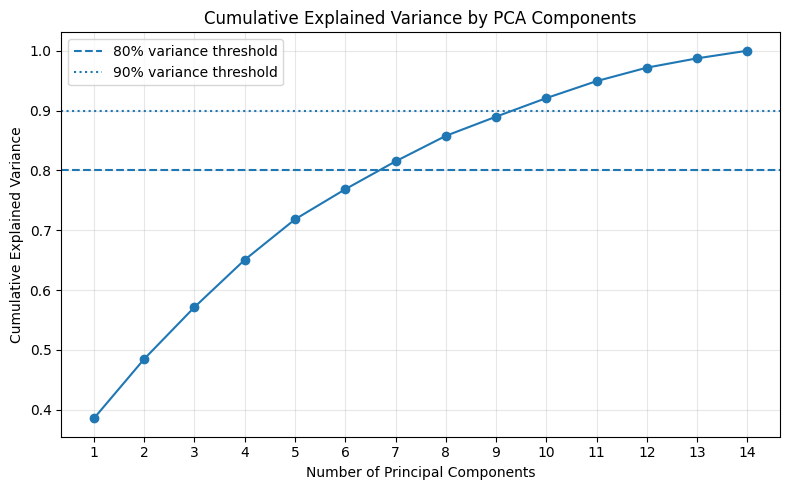

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.80, linestyle="--", label="80% variance threshold")
plt.axhline(y=0.90, linestyle=":", label="90% variance threshold")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance by PCA Components")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("pca_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()

The cumulative explained variance plot shows how much information is preserved as more principal components are included. The first principal component explains about 38.6% of the variance, while the first two components explain about 48.5%. More components are needed to preserve most of the dataset structure, which suggests that customer behaviour is influenced by several different factors rather than only one or two variables. However, the first two components are still useful for visualising broad customer patterns in two dimensions.

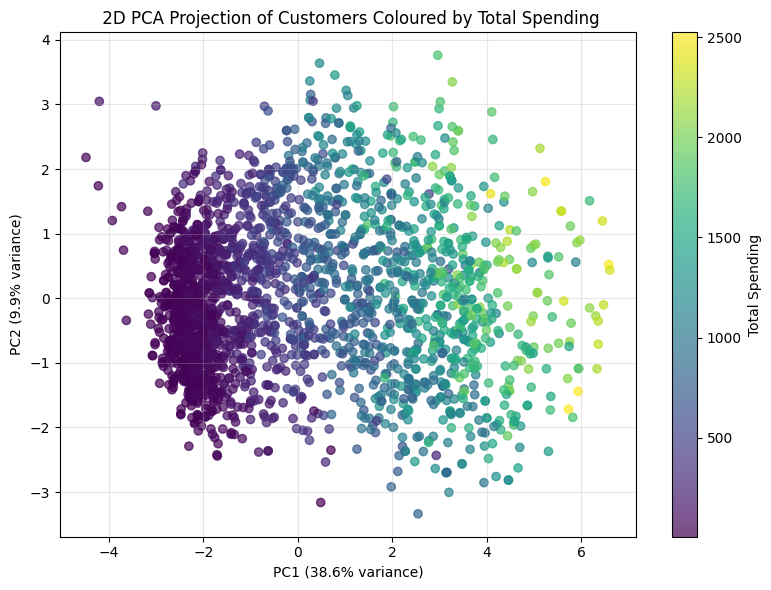

In [32]:
pca_df = pd.DataFrame(
    X_pca[:, :2],
    columns=["PC1", "PC2"],
    index=df_clean.index
)

pca_df["Total_Spending"] = df_clean["Total_Spending"]

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["Total_Spending"],
    alpha=0.7
)

plt.colorbar(scatter, label="Total Spending")
plt.xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
plt.title(" 2D PCA Projection of Customers Coloured by Total Spending")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("pca_2d_spending.png", dpi=300, bbox_inches="tight")
plt.show()

The PCA projection shows customers in the space of the first two principal components, with points coloured by total spending. A visible colour gradient along PC1 would suggest that the first component is strongly related to customer value and spending behaviour. This helps interpret the meaning of the main PCA directions before clustering.

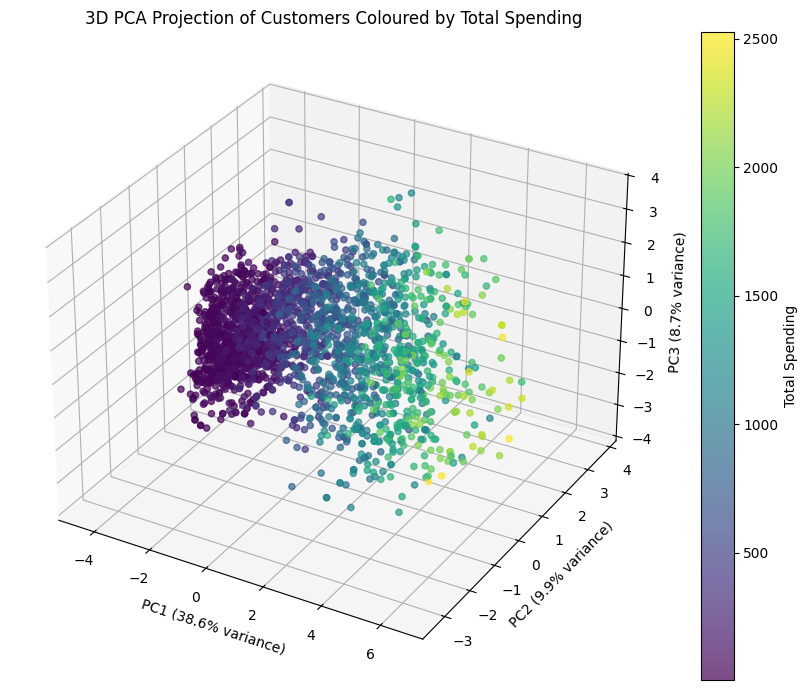

In [33]:
from mpl_toolkits.mplot3d import Axes3D

pca_3d_df = pd.DataFrame(
    X_pca[:, :3],
    columns=["PC1", "PC2", "PC3"],
    index=df_clean.index
)

pca_3d_df["Total_Spending"] = df_clean["Total_Spending"]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    pca_3d_df["PC1"],
    pca_3d_df["PC2"],
    pca_3d_df["PC3"],
    c=pca_3d_df["Total_Spending"],
    alpha=0.7
)

fig.colorbar(scatter, ax=ax, label="Total Spending")

ax.set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
ax.set_zlabel(f"PC3 ({explained_variance[2]*100:.1f}% variance)")

ax.set_title("3D PCA Projection of Customers Coloured by Total Spending")

plt.tight_layout()
fig.savefig("pca_3d_spending.png", dpi=300, bbox_inches="tight")
plt.show()

The 3D PCA projection uses the first three principal components, which together explain approximately 57.2% of the variance. This retains more information than the 2D plot while still reducing the original 14 numerical features to three dimensions. The colour gradient still shows that higher-spending customers are generally separated from lower-spending customers, especially along PC1. However, even the 3D projection does not capture the full dataset structure, so the cumulative variance plot remains important for showing that around seven components are needed to preserve approximately 80% of the variance.

### PCA loadings

PCA loadings were used to understand which original variables contributed most to the first two principal components. This helps interpret what PC1 and PC2 represent in terms of customer behaviour.

In [34]:
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(len(pca_features))],
    index=pca_features
)

loadings[["PC1", "PC2" , "PC3"]].sort_values(by="PC1", ascending=False)

,PC1,PC2,PC3
Income,0.362416,-0.051340,0.265233
MntMeatProducts,0.352112,-0.062424,-0.051538
Total_Purchases,0.327690,0.286796,0.168897
MntWines,0.323887,0.290638,0.198646
MntFishProducts,0.319661,-0.107725,-0.180805
MntFruits,0.309112,-0.111734,-0.197561
MntSweetProducts,0.308633,-0.092931,-0.174750
MntGoldProds,0.250093,0.201326,-0.086965
Accepted_Campaigns,0.183216,0.245721,0.017006
Age,0.054361,0.105320,0.718880


The PCA loadings show that PC1 is mainly associated with income, product spending, and total purchases. Therefore, PC1 can be interpreted as an overall customer value or spending behaviour dimension. Customers with higher PC1 scores tend to have higher income and higher spending across several product categories. PC1 also has negative loadings for total children and monthly web visits, suggesting that customers with more children or frequent website visits are generally lower on this spending-value dimension.

PC2 is most strongly associated with customer tenure, website visits, total purchases, and campaign acceptance. This suggests that PC2 captures customer engagement or activity behaviour rather than pure spending. Customers with higher PC2 scores tend to have longer tenure, more website visits, and greater interaction with purchases or campaigns.

PC3 is mainly associated with age, with a much larger loading than the other features. It also has some contribution from total children and income, while customer tenure has a negative loading. This suggests that PC3 captures an age and demographic structure dimension. Overall, PCA shows that the main variation in the dataset is driven by customer value, while secondary patterns relate to customer engagement and demographic differences.

## 6. Clustering

K-Means clustering was used to group customers into behavioural segments based on the same standardised numerical features used for the main PCA. The elbow method and silhouette scores were used to compare possible values of \(k\), and the final clusters were interpreted using average customer profiles.


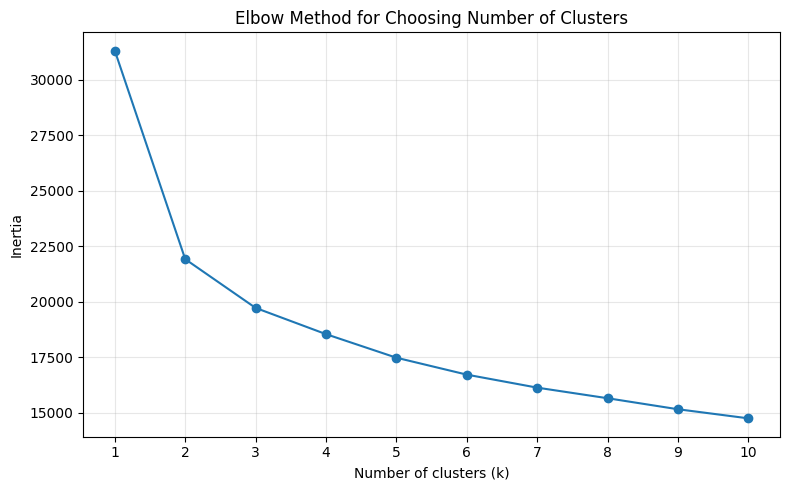

In [35]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("kmeans_elbow_plot.png", dpi=300, bbox_inches="tight")
plt.show()

The elbow plot shows how within-cluster inertia decreases as the number of clusters increases. The largest improvement occurs when moving from one to two clusters, and the curve begins to flatten after around three clusters. This suggests that \(k=3\) is a reasonable choice for exploratory customer segmentation.

### Silhouette score comparison

Silhouette scores were calculated for different values of \(k\) to compare how clearly separated the clusters were. Higher silhouette scores indicate better-separated clusters, although the final choice of \(k\) also needs to make sense for customer interpretation.

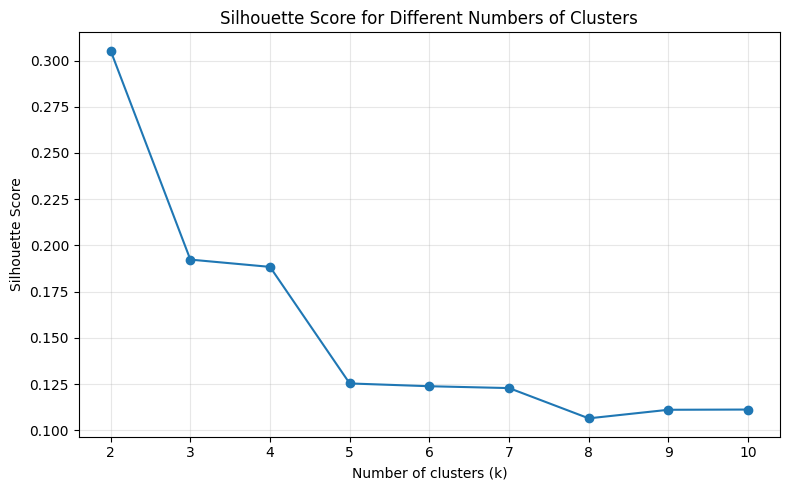

In [36]:
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Numbers of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("kmeans_silhouette_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
silhouette_table = pd.DataFrame({
    "k": list(k_values),
    "Silhouette Score": silhouette_scores
})

silhouette_table.round(3)

,k,Silhouette Score
0,2,0.305
1,3,0.192
2,4,0.188
3,5,0.125
4,6,0.124
5,7,0.123
6,8,0.106
7,9,0.111
8,10,0.111


The silhouette score helps evaluate cluster separation. Although the highest score may occur for a smaller number of clusters, the final value of \(k\) should also produce meaningful customer segments. In this analysis, \(k=3\) was selected because it provides a useful business interpretation: low-value, mid-value, and high-value customer groups.

In [38]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)

df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

df_clean["Cluster"].value_counts().sort_index()

Cluster
0    1068
1     551
2     617
Name: count, dtype: int64

The silhouette score is highest for \(k=2\), which means two clusters provide the clearest mathematical separation. However, \(k=3\) was selected for the final segmentation because it provides a more useful customer interpretation: low-value, mid-value, and high-value customers. The cluster sizes are reasonably balanced, so all three groups contain enough customers to analyse meaningfully.

### 2D cluster visualisation

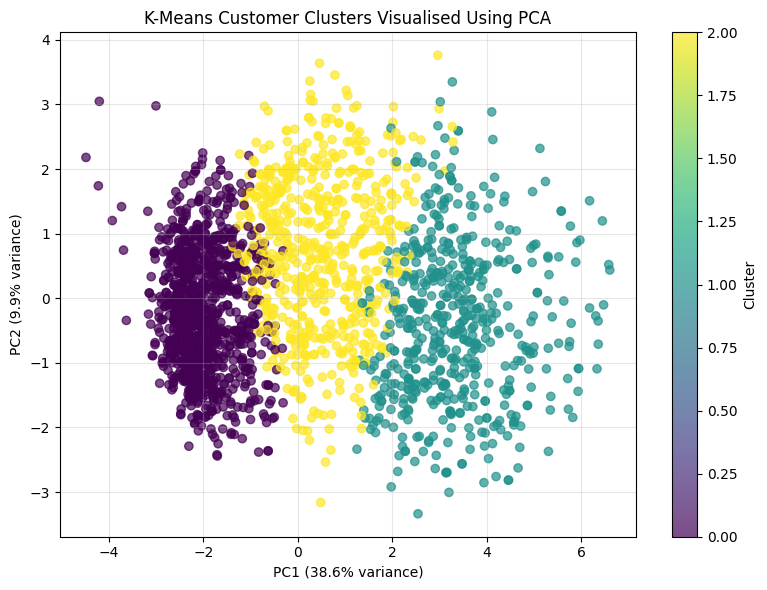

In [39]:
pca_cluster_df = pd.DataFrame(
    X_pca[:, :2],
    columns=["PC1", "PC2"],
    index=df_clean.index
)

pca_cluster_df["Cluster"] = df_clean["Cluster"]

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    pca_cluster_df["PC1"],
    pca_cluster_df["PC2"],
    c=pca_cluster_df["Cluster"],
    alpha=0.7
)

plt.colorbar(scatter, label="Cluster")
plt.xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
plt.title("K-Means Customer Clusters Visualised Using PCA")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("kmeans_pca_clusters_2d.png", dpi=300, bbox_inches="tight")
plt.show()

The 2D cluster plot shows how the K-Means clusters are arranged in the first two principal components. The clusters separate mainly along PC1, which was previously interpreted as a customer value and spending dimension. This suggests that the clustering is strongly influenced by differences in income, spending, and purchase behaviour.

### 3D cluster visualisation

A 3D PCA cluster plot was also created using PC1, PC2, and PC3. This includes more variance than the 2D plot and provides an additional visual check of how the K-Means clusters are separated in reduced PCA space.

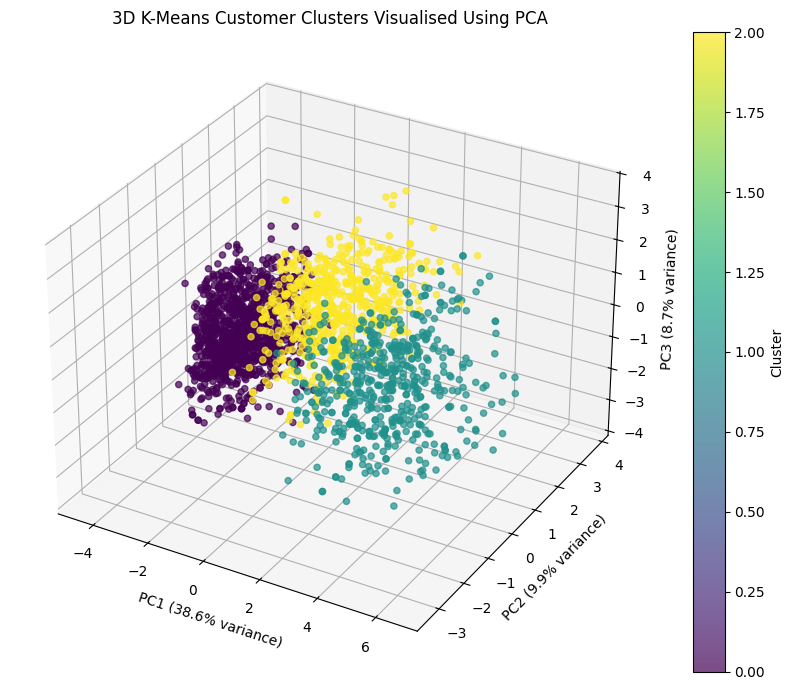

In [40]:
pca_cluster_3d_df = pd.DataFrame(
    X_pca[:, :3],
    columns=["PC1", "PC2", "PC3"],
    index=df_clean.index
)

pca_cluster_3d_df["Cluster"] = df_clean["Cluster"]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    pca_cluster_3d_df["PC1"],
    pca_cluster_3d_df["PC2"],
    pca_cluster_3d_df["PC3"],
    c=pca_cluster_3d_df["Cluster"],
    alpha=0.7
)

fig.colorbar(scatter, ax=ax, label="Cluster")

ax.set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
ax.set_zlabel(f"PC3 ({explained_variance[2]*100:.1f}% variance)")

ax.set_title("3D K-Means Customer Clusters Visualised Using PCA")

plt.tight_layout()
fig.savefig("kmeans_pca_clusters_3d.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
cluster_profile = df_clean.groupby("Cluster")[
    [
        "Income",
        "Age",
        "Total_Children",
        "Customer_Tenure_Months",
        "Recency",
        "Total_Spending",
        "Total_Purchases",
        "NumWebVisitsMonth",
        "Accepted_Campaigns"
    ]
].mean().round(2)

cluster_names = {
    0: "Low-spending browsers",
    1: "High-value premium customers",
    2: "Regular mid-value customers"
}

cluster_profile_named = cluster_profile.copy()
cluster_profile_named.index = cluster_profile_named.index.map(cluster_names)

cluster_profile_named

,Income,Age,Total_Children,Customer_Tenure_Months,Recency,Total_Spending,Total_Purchases,NumWebVisitsMonth,Accepted_Campaigns
Cluster,,,,,,,,,
Low-spending browsers,35052.58,42.59,1.26,10.14,49.23,104.21,8.21,6.50,0.18
High-value premium customers,76289.83,45.09,0.22,11.45,49.86,1397.46,20.97,2.81,0.99
Regular mid-value customers,59471.96,49.45,1.07,12.81,48.26,767.73,20.96,5.52,0.43


The cluster profile table gives the final interpretation of the customer segments. 

`Low-spending browsers` have the lowest income, lowest total spending, lowest purchase count, and the highest number of monthly web visits. This suggests that these customers interact with the website but do not convert strongly into purchases.

`High-value premium customers` have the highest income, highest total spending, highest campaign acceptance, and the fewest children at home. This group is the most valuable segment because they spend substantially more and are more responsive to marketing campaigns.

`Regular mid-value customers` have medium income and medium total spending, but their purchase count is similar to the premium group. This suggests that they buy regularly, but their overall spending is lower than the high-value segment.

Recency is similar across all three clusters, which suggests that the number of days since the last purchase does not strongly separate the customer groups.

## 7. Conclusion or Reflection

This exploratory data analysis showed that the Customer Personality Analysis dataset is suitable for customer behaviour analysis because it contains a mixture of demographic, spending, purchasing, and marketing response variables. After cleaning, the final dataset contained 2236 customer records with no missing values.

The visualisation stage showed that income and product spending vary noticeably across customers. Wine and meat products had the highest average spending, while store and web purchases were important purchase channels. Campaign response was relatively low, showing that most customers did not accept the final marketing campaign.

Feature engineering was important because it transformed several raw columns into clearer customer-level variables. Features such as `Total_Spending`, `Total_Purchases`, `Total_Children`, `Customer_Tenure_Months`, and `Accepted_Campaigns` made the dataset easier to interpret. The raw vs engineered PCA comparison showed that engineered features gave a more compact representation of customer behaviour, because fewer components were needed to preserve most of the variance.

PCA showed that the main source of variation in the dataset was related to customer value and spending behaviour. PC1 was mainly associated with income, product spending, and total purchases. PC2 was more related to customer tenure, website visits, purchases, and campaign response, while PC3 was mainly linked to age and demographic structure. The first two components were useful for visualisation, but around seven principal components were needed to preserve approximately 80% of the variance.

K-Means clustering identified three interpretable customer segments: low-spending browsers, high-value premium customers, and regular mid-value customers. The silhouette score showed that the clusters were not perfectly separated, so the segments should be interpreted as broad behavioural groups rather than strict categories. However, the cluster profile table showed meaningful differences in income, spending, purchases, web visits, children at home, and campaign acceptance.

Overall, this project showed that combining data processing, visualisation, feature engineering, PCA, and clustering can produce useful insights from customer data. The main limitation is that the analysis is exploratory and does not prove causation. For example, higher income is associated with higher spending, but this does not prove that income alone causes spending behaviour. Future work could explore predictive modelling or test additional segmentation methods to compare with K-Means.